# Liquidez sin colocar: el costo invisible de CESCA en 2025

Análisis de los estados financieros comparativos 2025–2024 de CESCA Cooperativa de Ahorro y Crédito.

**Pregunta:** ¿por qué una cooperativa sólida y con liquidez creciente generó 21% menos excedente en 2025?

Cifras en millones de pesos colombianos. Fuente: Informe de Gestión CESCA, vigencia 2025.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATOS = Path("../datos")
GRAFICAS = Path("../graficas")
GRAFICAS.mkdir(exist_ok=True)

cifras = pd.read_csv(DATOS / "cifras_estados_financieros.csv").set_index("concepto")
supuestos = pd.read_csv(DATOS / "supuestos.csv").set_index("parametro")

def v(concepto, anio=2025):
    return cifras.loc[concepto, f"valor_{anio}"]

VERDE, VERDE_CLARO, AZUL, GRIS, ROJO = "#6A9E1F", "#B5D67A", "#1F3B57", "#9AA5B1", "#C0504D"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 11})

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(GRAFICAS / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

cifras.head()

,categoria,valor_2024,valor_2025,unidad,fuente
concepto,,,,,
efectivo_y_equivalentes,liquidez,30855.6,34194.0,millones_cop,Estado de situación financiera / Nota 5
equivalentes_cdt,liquidez,12409.9,18811.6,millones_cop,Nota 5
fondo_liquidez,liquidez,4960.0,5377.4,millones_cop,Nota 5
inversiones_corto_plazo,liquidez,528.2,9277.5,millones_cop,Estado de situación financiera / Nota 6
cartera_neta,activo,83639.3,84342.5,millones_cop,Nota 7


## 1. La liquidez gana espacio a la cartera

In [2]:
liquidez = {a: v("efectivo_y_equivalentes", a) + v("inversiones_corto_plazo", a) for a in (2024, 2025)}

crecimiento = pd.Series({
    "Liquidez (efectivo + inv. CP)": liquidez[2025] / liquidez[2024] - 1,
    "Aportes sociales": v("aportes_sociales") / v("aportes_sociales", 2024) - 1,
    "Depósitos": v("depositos_asociados") / v("depositos_asociados", 2024) - 1,
    "Cartera bruta": v("cartera_bruta_capital") / v("cartera_bruta_capital", 2024) - 1,
}) * 100

print(f"Liquidez 2024: ${liquidez[2024]:,.0f}M  |  2025: ${liquidez[2025]:,.0f}M")
crecimiento.round(1)

Liquidez 2024: $31,384M  |  2025: $43,472M


Liquidez (efectivo + inv. CP)    38.5
Aportes sociales                 12.3
Depósitos                         9.4
Cartera bruta                     1.0
dtype: float64

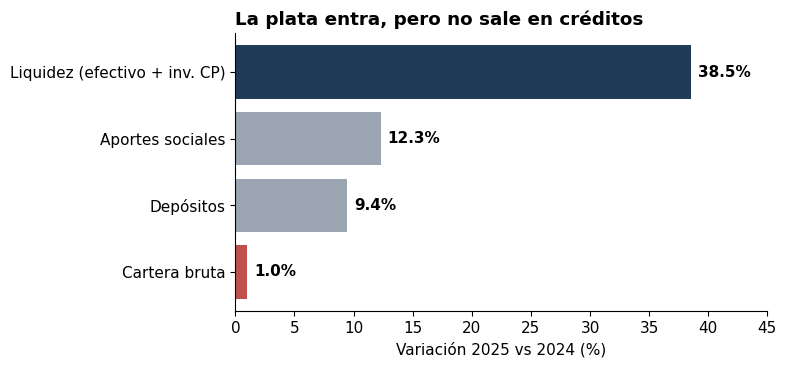

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
s = crecimiento.sort_values()
barras = ax.barh(s.index, s.values, color=[ROJO, GRIS, GRIS, AZUL])
for b, val in zip(barras, s.values):
    ax.text(val + 0.6, b.get_y() + b.get_height() / 2, f"{val:.1f}%", va="center", fontweight="bold")
ax.set_xlim(0, 45)
ax.set_xlabel("Variación 2025 vs 2024 (%)")
ax.set_title("La plata entra, pero no sale en créditos")
guardar(fig, "01_crecimiento")

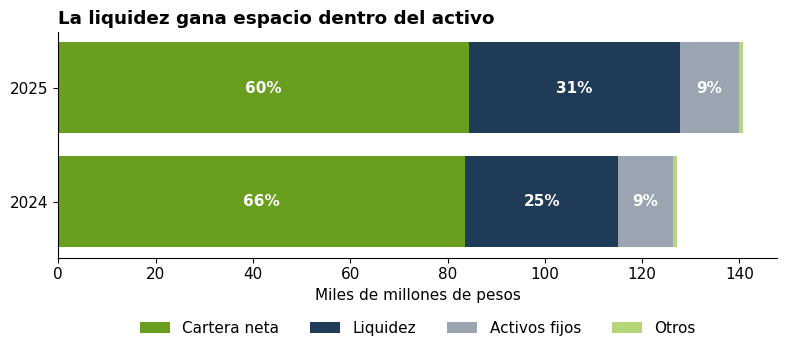

In [4]:
composicion = pd.DataFrame({
    a: {"Cartera neta": v("cartera_neta", a), "Liquidez": liquidez[a],
        "Activos fijos": v("activos_materiales", a), "Otros": v("otros_activos", a)}
    for a in (2024, 2025)}).T / 1000

fig, ax = plt.subplots(figsize=(8, 3.8))
izq = pd.Series(0.0, index=composicion.index)
for col, color in zip(composicion.columns, [VERDE, AZUL, GRIS, VERDE_CLARO]):
    ax.barh(composicion.index.astype(str), composicion[col], left=izq, color=color, label=col)
    for i, (anio, val) in enumerate(composicion[col].items()):
        pct = val / composicion.loc[anio].sum() * 100
        if pct > 6:
            ax.text(izq[anio] + val / 2, i, f"{pct:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    izq += composicion[col]
ax.set_xlabel("Miles de millones de pesos")
ax.set_title("La liquidez gana espacio dentro del activo")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
guardar(fig, "02_composicion_activo")

## 2. Costo de oportunidad de la liquidez

Un peso prestado rinde la tasa de cartera menos la pérdida esperada y el costo operativo. Un peso en CDT rinde ~9%.
Se aplica el diferencial solo a las inversiones en CDT a más de 90 días, que es el excedente de liquidez más claro.

In [5]:
tasa_cartera = v("tasa_promedio_cartera")
rend_cdt = supuestos.loc["rendimiento_cdt", "central"]
pe, co = supuestos.loc["perdida_esperada"], supuestos.loc["costo_operativo_marginal"]

dif_min = tasa_cartera - pe["maximo"] - co["maximo"] - rend_cdt
dif_max = tasa_cartera - pe["minimo"] - co["minimo"] - rend_cdt
print(f"Diferencial calculado: {dif_min:.2f} a {dif_max:.2f} pp  ->  se usa 4-6 pp (redondeo prudente)")

base = v("inversiones_corto_plazo")
dif = supuestos.loc["diferencial_neto", ["minimo", "central", "maximo"]]
costo = (base * dif / 100).round(0)
caida_excedente = v("excedente_neto", 2024) - v("excedente_neto")
print(f"Base: ${base:,.0f}M")
print(costo.rename({"minimo": "4%", "central": "5%", "maximo": "6%"}))
print(f"Caída real del excedente: ${caida_excedente:,.0f}M")

Diferencial calculado: 4.53 a 6.53 pp  ->  se usa 4-6 pp (redondeo prudente)
Base: $9,278M
4%    371.0
5%    464.0
6%    557.0
Name: diferencial_neto, dtype: float64
Caída real del excedente: $490M


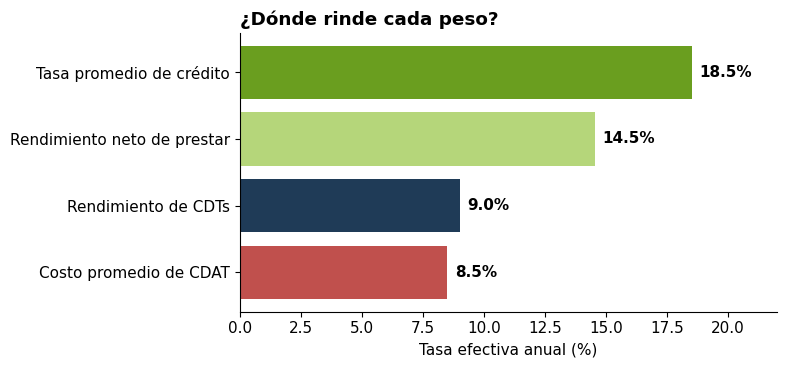

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
conceptos = ["Tasa promedio de crédito", "Rendimiento neto de prestar", "Rendimiento de CDTs", "Costo promedio de CDAT"]
tasas = [tasa_cartera, (tasa_cartera - pe["central"] - co["central"]), rend_cdt, v("tasa_promedio_cdat")]
barras = ax.barh(conceptos[::-1], tasas[::-1], color=[ROJO, AZUL, VERDE_CLARO, VERDE])
for b, t in zip(barras, tasas[::-1]):
    ax.text(t + 0.3, b.get_y() + b.get_height() / 2, f"{t:.1f}%", va="center", fontweight="bold")
ax.set_xlim(0, 22)
ax.set_xlabel("Tasa efectiva anual (%)")
ax.set_title("¿Dónde rinde cada peso?")
guardar(fig, "03_rendimientos")

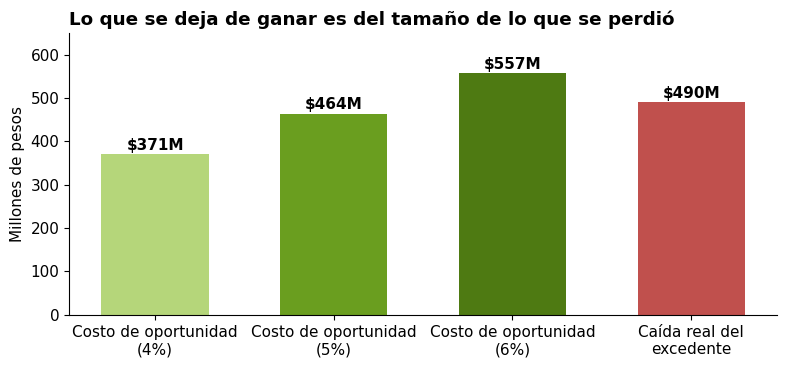

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
etiquetas = ["Costo de oportunidad\n(4%)", "Costo de oportunidad\n(5%)", "Costo de oportunidad\n(6%)", "Caída real del\nexcedente"]
valores = list(costo.values) + [caida_excedente]
barras = ax.bar(etiquetas, valores, color=[VERDE_CLARO, VERDE, "#4E7A12", ROJO], width=0.6)
for b, val in zip(barras, valores):
    ax.text(b.get_x() + b.get_width() / 2, val + 10, f"${val:,.0f}M", ha="center", fontweight="bold")
ax.set_ylim(0, 650)
ax.set_ylabel("Millones de pesos")
ax.set_title("Lo que se deja de ganar es del tamaño de lo que se perdió")
guardar(fig, "04_costo_oportunidad")

### Sensibilidad: excedente adicional según cuánto se coloque

In [8]:
sensibilidad = pd.DataFrame(
    {f"Diferencial {d:.0f}%": [base * p * d / 100 for p in (0.25, 0.5, 0.75, 1)] for d in dif.values},
    index=["25%", "50%", "75%", "100%"]).round(0)
sensibilidad.index.name = "% de liquidez colocada"
sensibilidad

,Diferencial 4%,Diferencial 5%,Diferencial 6%
% de liquidez colocada,,,
25%,93.0,116.0,139.0
50%,186.0,232.0,278.0
75%,278.0,348.0,417.0
100%,371.0,464.0,557.0


## 3. Captar sin colocar casi no deja margen

Lo que CESCA paga por sus CDAT frente a lo que recibe al invertir en CDTs.

In [9]:
margen = rend_cdt - v("tasa_promedio_cdat")
print(f"Costo CDAT: {v('tasa_promedio_cdat'):.2f}%  |  Rendimiento CDT: {rend_cdt:.2f}%  |  Margen bruto: {margen:.2f} pp")
print("Antes de GMF, prima Fogacoop, contribución Supersolidaria y gasto administrativo.")

Costo CDAT: 8.50%  |  Rendimiento CDT: 9.00%  |  Margen bruto: 0.50 pp
Antes de GMF, prima Fogacoop, contribución Supersolidaria y gasto administrativo.


## 4. ¿Funcionó bajar la tasa de crédito?

Si ingresos ≈ cartera × tasa, para mantener los ingresos con una tasa menor la cartera debía crecer en la misma proporción.

In [10]:
t0, t1 = v("tasa_promedio_cartera", 2024), v("tasa_promedio_cartera")
crec_necesario = (t0 / t1 - 1) * 100
crec_real = crecimiento["Cartera bruta"]
cambio_intereses = v("intereses_cartera") - v("intereses_cartera", 2024)
print(f"Crecimiento necesario: {crec_necesario:.2f}%  |  real: {crec_real:.2f}%")
print(f"Cambio en intereses de cartera: ${cambio_intereses:,.0f}M")

Crecimiento necesario: 4.48%  |  real: 0.96%
Cambio en intereses de cartera: $-427M


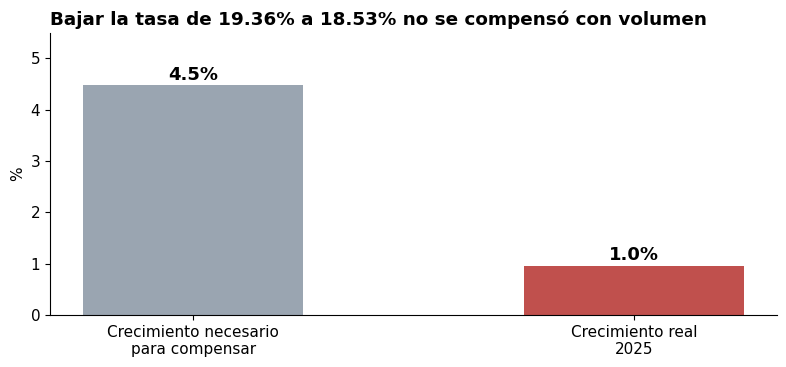

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
barras = ax.bar(["Crecimiento necesario\npara compensar", "Crecimiento real\n2025"], [crec_necesario, crec_real], color=[GRIS, ROJO], width=0.5)
for b, val in zip(barras, [crec_necesario, crec_real]):
    ax.text(b.get_x() + b.get_width() / 2, val + 0.1, f"{val:.1f}%", ha="center", fontweight="bold", fontsize=13)
ax.set_ylim(0, 5.5)
ax.set_ylabel("%")
ax.set_title(f"Bajar la tasa de {t0:.2f}% a {t1:.2f}% no se compensó con volumen")
guardar(fig, "05_punto_equilibrio")

## 5. Escenarios ilustrativos 2026

Cada escenario cambia una sola variable sobre el excedente 2025; todo lo demás se mantiene constante.

In [12]:
exc_2025 = v("excedente_neto")
invertido = v("equivalentes_cdt") + v("inversiones_corto_plazo") + v("fondo_liquidez")
d = supuestos.loc["diferencial_neto", "central"] / 100
delta_tasa = supuestos.loc["cambio_tasa_inversion", "central"] / 100

escenarios = pd.Series({
    "2024 real": v("excedente_neto", 2024),
    "2025 real": exc_2025,
    "A. Sin cambios": exc_2025,
    "A2. Tasas −1 pp": exc_2025 + invertido * delta_tasa,
    "B. Colocar 50%": exc_2025 + base * 0.5 * d,
    "C. Colocar 100%": exc_2025 + base * d,
}).round(0)
escenarios

2024 real          2351.0
2025 real          1861.0
A. Sin cambios     1861.0
A2. Tasas −1 pp    1526.0
B. Colocar 50%     2093.0
C. Colocar 100%    2325.0
dtype: float64

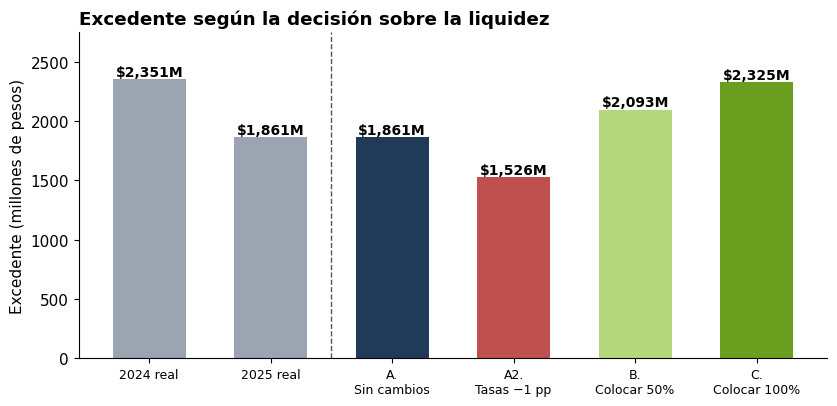

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
barras = ax.bar([e.replace(". ", ".\n") for e in escenarios.index], escenarios.values,
                color=[GRIS, GRIS, AZUL, ROJO, VERDE_CLARO, VERDE], width=0.6)
for b, val in zip(barras, escenarios.values):
    ax.text(b.get_x() + b.get_width() / 2, val + 30, f"${val:,.0f}M", ha="center", fontsize=10, fontweight="bold")
ax.axvline(1.5, color="#555", linestyle="--", linewidth=1)
ax.set_ylim(0, 2750)
ax.set_ylabel("Excedente (millones de pesos)")
ax.set_title("Excedente según la decisión sobre la liquidez")
plt.setp(ax.get_xticklabels(), fontsize=9)
guardar(fig, "06_escenarios")

## Conclusiones

1. La liquidez creció 38,5% y la cartera 1,0%: la liquidez pasó del 25% al 31% del activo.
2. El costo de oportunidad de los CDT a más de 90 días se estima entre $371M y $557M al año, similar a la caída del excedente ($490M).
3. El ahorro captado al 8,5% e invertido al ~9% casi no deja margen.
4. La baja de tasa exigía crecer 4,5%; la cartera creció 1,0%. La demanda no parece responder principalmente al precio.
5. Colocar el 100% del excedente de liquidez llevaría el excedente cerca del nivel de 2024.

**Limitaciones:** dos periodos, datos agregados, tasas promedio y supuestos de pérdida esperada y costo operativo.